# Experiment 9 — Data Distribution

## Four Distributions Covered

| Distribution | Shape | Real-World Example | Key Parameters |
|---|---|---|---|
| **Normal** | Symmetric bell curve | Exam scores, heights | µ (mean), σ (std dev) |
| **Right-Skewed** | Tail on the right | Salaries, house prices | Mean > Median > Mode |
| **Uniform** | Flat / equal probability | Dice rolls, random IDs | a (min), b (max) |
| **Binomial** | Discrete bar chart | Pass/Fail, Heads/Tails | n (trials), p (probability) |

**Dataset:** 1000 samples per distribution  
**Goal:** Visualise shape, compute statistics, understand behaviour


In [1]:
# ── 0. Imports ─────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch
import os, warnings
warnings.filterwarnings('ignore')

np.random.seed(21)
output_dir = os.getcwd()
N = 1000

print('Libraries loaded ✓')

Libraries loaded ✓


---
## 1. Generate All Four Distributions

In [2]:
# ── 1. Data Generation ─────────────────────────────────────────────────────────

# 1. Normal Distribution — exam scores (µ=70, σ=10)
normal_data = np.random.normal(loc=70, scale=10, size=N)
normal_data = np.clip(normal_data, 0, 100)

# 2. Right-Skewed Distribution — monthly salaries in ₹000s
#    Using log-normal: exp of normal → creates a right tail
skewed_data = np.random.lognormal(mean=3.5, sigma=0.6, size=N)   # ≈ ₹20k–₹200k range

# 3. Uniform Distribution — random wait times in minutes (0 to 30)
uniform_data = np.random.uniform(low=0, high=30, size=N)

# 4. Binomial Distribution — number of successful sales out of 20 calls (p=0.35)
binom_data = np.random.binomial(n=20, p=0.35, size=N)

# Store in a dict for easy access
distributions = {
    'Normal':        normal_data,
    'Right-Skewed':  skewed_data,
    'Uniform':       uniform_data,
    'Binomial':      binom_data
}

print(f'Generated {N} samples for each distribution ✓')
for name, data in distributions.items():
    print(f'  {name:<14} → mean={data.mean():.2f}, std={data.std():.2f}, min={data.min():.2f}, max={data.max():.2f}')

Generated 1000 samples for each distribution ✓
  Normal         → mean=69.59, std=9.94, min=31.48, max=100.00
  Right-Skewed   → mean=39.69, std=25.36, min=5.84, max=183.82
  Uniform        → mean=15.21, std=8.58, min=0.05, max=29.91
  Binomial       → mean=6.96, std=2.15, min=1.00, max=14.00


In [3]:
# ── 2. Save dataset ────────────────────────────────────────────────────────────
df_dist = pd.DataFrame({
    'sample_id':          np.arange(1, N+1),
    'exam_score_normal':  np.round(normal_data, 2),
    'salary_skewed':      np.round(skewed_data, 2),
    'wait_time_uniform':  np.round(uniform_data, 2),
    'sales_binomial':     binom_data
})

df_dist.to_csv(os.path.join(output_dir, 'distribution_dataset.csv'), index=False)
print('Dataset saved → distribution_dataset.csv ✓')
df_dist.head(6)

Dataset saved → distribution_dataset.csv ✓


,sample_id,exam_score_normal,salary_skewed,wait_time_uniform,sales_binomial
0,1,69.48,83.62,17.36,10
1,2,68.89,35.07,13.03,5
2,3,80.42,50.32,9.93,6
3,4,57.43,15.85,28.62,9
4,5,77.45,51.01,22.46,10
5,6,52.89,10.04,16.27,6


---
## 2. Descriptive Statistics — All Four Distributions

In [4]:
# ── 3. Descriptive Statistics Table ───────────────────────────────────────────
def get_stats(data, name):
    skewness = stats.skew(data)
    kurt     = stats.kurtosis(data)   # excess kurtosis (normal=0)
    return {
        'Distribution': name,
        'N':            len(data),
        'Mean':         round(data.mean(), 3),
        'Median':       round(np.median(data), 3),
        'Std Dev':      round(data.std(), 3),
        'Min':          round(data.min(), 3),
        'Max':          round(data.max(), 3),
        'Skewness':     round(skewness, 3),
        'Kurtosis':     round(kurt, 3)
    }

stats_rows = [get_stats(d, n) for n, d in distributions.items()]
df_stats   = pd.DataFrame(stats_rows)

def color_skew(val):
    if isinstance(val, float):
        if val > 0.5:  return 'background-color:#FFE0B2'   # right skew — orange
        if val < -0.5: return 'background-color:#B3E5FC'   # left skew — blue
    return ''

(df_stats.style
 .applymap(color_skew, subset=['Skewness'])
 .set_caption('Descriptive Statistics — All Four Distributions')
 .set_properties(**{'text-align':'center','padding':'7px 14px','border':'1px solid #ddd'})
 .set_table_styles([{'selector':'th','props':'background-color:#2c3e50;color:white;text-align:center;padding:8px;'},
                    {'selector':'caption','props':'font-size:14px;font-weight:bold;padding-bottom:8px;'}])
)

,Distribution,N,Mean,Median,Std Dev,Min,Max,Skewness,Kurtosis
0,Normal,1000,69.594000,69.644000,9.942000,31.475000,100.000000,0.019000,0.145000
1,Right-Skewed,1000,39.695000,33.289000,25.361000,5.839000,183.823000,1.758000,4.329000
2,Uniform,1000,15.214000,15.566000,8.581000,0.045000,29.913000,-0.042000,-1.159000
3,Binomial,1000,6.957000,7.000000,2.152000,1.000000,14.000000,0.112000,-0.194000


---
## 3. Distribution 1 — Normal Distribution

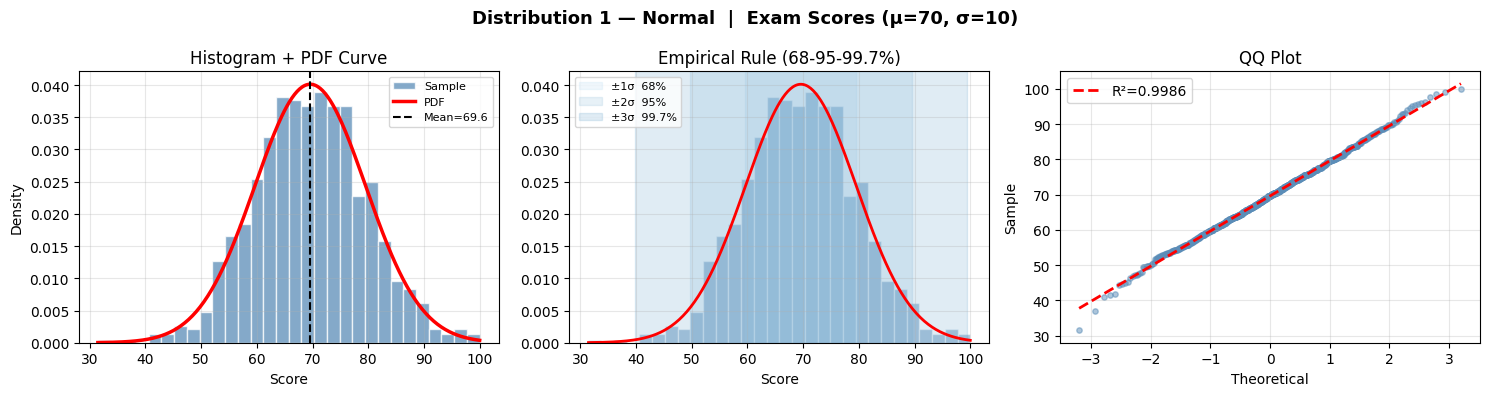

Shapiro-Wilk: W=0.9937, p=0.5566 → Normal ✓
Skewness: 0.0194  |  Kurtosis (excess): 0.1450


In [5]:
# ── 4. Normal Distribution ─────────────────────────────────────────────────────
data   = normal_data
mu, sd = data.mean(), data.std()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribution 1 — Normal  |  Exam Scores (µ=70, σ=10)', fontsize=13, fontweight='bold')

# Histogram + PDF curve
ax = axes[0]
ax.hist(data, bins=30, density=True, color='#5B8DB8', alpha=0.75, edgecolor='white', label='Sample')
x  = np.linspace(data.min(), data.max(), 300)
ax.plot(x, stats.norm.pdf(x, mu, sd), 'r-', lw=2.5, label='PDF')
ax.axvline(mu, color='black', ls='--', lw=1.5, label=f'Mean={mu:.1f}')
ax.set_title('Histogram + PDF Curve'); ax.set_xlabel('Score'); ax.set_ylabel('Density')
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# Empirical Rule — 1σ, 2σ, 3σ bands
ax2 = axes[1]
ax2.hist(data, bins=30, density=True, color='#5B8DB8', alpha=0.5, edgecolor='white')
ax2.plot(x, stats.norm.pdf(x, mu, sd), 'r-', lw=2)
for n_sig, col, label in [(1,'#AED6F1','68%'),(2,'#7FB3D3','95%'),(3,'#5499C7','99.7%')]:
    ax2.axvspan(mu - n_sig*sd, mu + n_sig*sd, alpha=0.18, color=col, label=f'±{n_sig}σ  {label}')
ax2.set_title('Empirical Rule (68-95-99.7%)'); ax2.set_xlabel('Score')
ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

# QQ Plot
ax3 = axes[2]
(osm, osr), (slope, intercept, r) = stats.probplot(data)
ax3.scatter(osm, osr, color='#5B8DB8', alpha=0.5, s=15)
ax3.plot(osm, slope*np.array(osm)+intercept, 'r--', lw=2, label=f'R²={r**2:.4f}')
ax3.set_title('QQ Plot'); ax3.set_xlabel('Theoretical'); ax3.set_ylabel('Sample')
ax3.legend(); ax3.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'dist_normal.png'), dpi=150, bbox_inches='tight')
plt.show()

# Shapiro-Wilk
w, p = stats.shapiro(data[:200])   # Shapiro is most reliable for n≤200
print(f'Shapiro-Wilk: W={w:.4f}, p={p:.4f} → {"Normal ✓" if p>0.05 else "Non-normal ✗"}')
print(f'Skewness: {stats.skew(data):.4f}  |  Kurtosis (excess): {stats.kurtosis(data):.4f}')

---
## 4. Distribution 2 — Right-Skewed Distribution

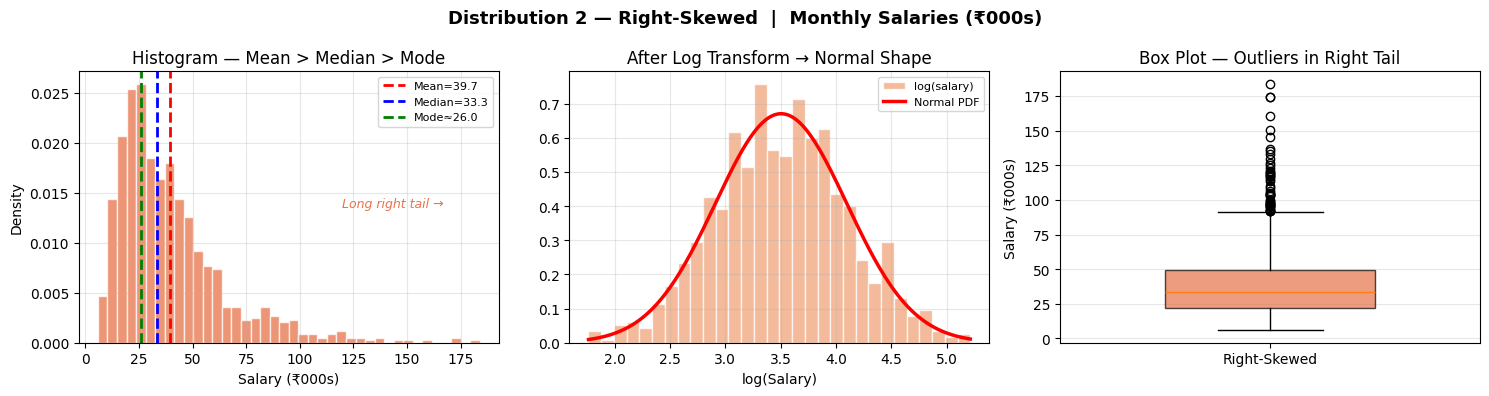

Skewness: 1.7580  (positive = right tail)
Mean=39.69  |  Median=33.29  |  Mode≈26.00
Order confirms right skew: Mean > Median > Mode → 39.7 > 33.3 > 26.0


In [6]:
# ── 5. Right-Skewed (Log-Normal) Distribution ──────────────────────────────────
data   = skewed_data
mean_  = data.mean()
median_= np.median(data)
mode_  = float(stats.mode(np.round(data)).mode)   # approximate mode

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribution 2 — Right-Skewed  |  Monthly Salaries (₹000s)', fontsize=13, fontweight='bold')

# Histogram showing skew
ax = axes[0]
ax.hist(data, bins=40, density=True, color='#E8734A', alpha=0.75, edgecolor='white')
ax.axvline(mean_,   color='red',    lw=2, ls='--', label=f'Mean={mean_:.1f}')
ax.axvline(median_, color='blue',   lw=2, ls='--', label=f'Median={median_:.1f}')
ax.axvline(mode_,   color='green',  lw=2, ls='--', label=f'Mode≈{mode_:.1f}')
ax.set_title('Histogram — Mean > Median > Mode'); ax.set_xlabel('Salary (₹000s)'); ax.set_ylabel('Density')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.annotate('Long right tail →', xy=(data.max()*0.65, ax.get_ylim()[1]*0.5),
            fontsize=9, color='#E8734A', style='italic')

# Log-transformed → becomes Normal
ax2 = axes[1]
log_data = np.log(data)
ax2.hist(log_data, bins=30, density=True, color='#F0A57A', alpha=0.75, edgecolor='white', label='log(salary)')
mu_log, sd_log = log_data.mean(), log_data.std()
x = np.linspace(log_data.min(), log_data.max(), 300)
ax2.plot(x, stats.norm.pdf(x, mu_log, sd_log), 'r-', lw=2.5, label='Normal PDF')
ax2.set_title('After Log Transform → Normal Shape'); ax2.set_xlabel('log(Salary)')
ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

# Box plot showing outliers
ax3 = axes[2]
bp = ax3.boxplot(data, vert=True, patch_artist=True, widths=0.5)
bp['boxes'][0].set_facecolor('#E8734A'); bp['boxes'][0].set_alpha(0.7)
ax3.set_title('Box Plot — Outliers in Right Tail'); ax3.set_ylabel('Salary (₹000s)')
ax3.set_xticklabels(['Right-Skewed']); ax3.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'dist_skewed.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'Skewness: {stats.skew(data):.4f}  (positive = right tail)')
print(f'Mean={mean_:.2f}  |  Median={median_:.2f}  |  Mode≈{mode_:.2f}')
print(f'Order confirms right skew: Mean > Median > Mode → {mean_:.1f} > {median_:.1f} > {mode_:.1f}')

---
## 5. Distribution 3 — Uniform Distribution

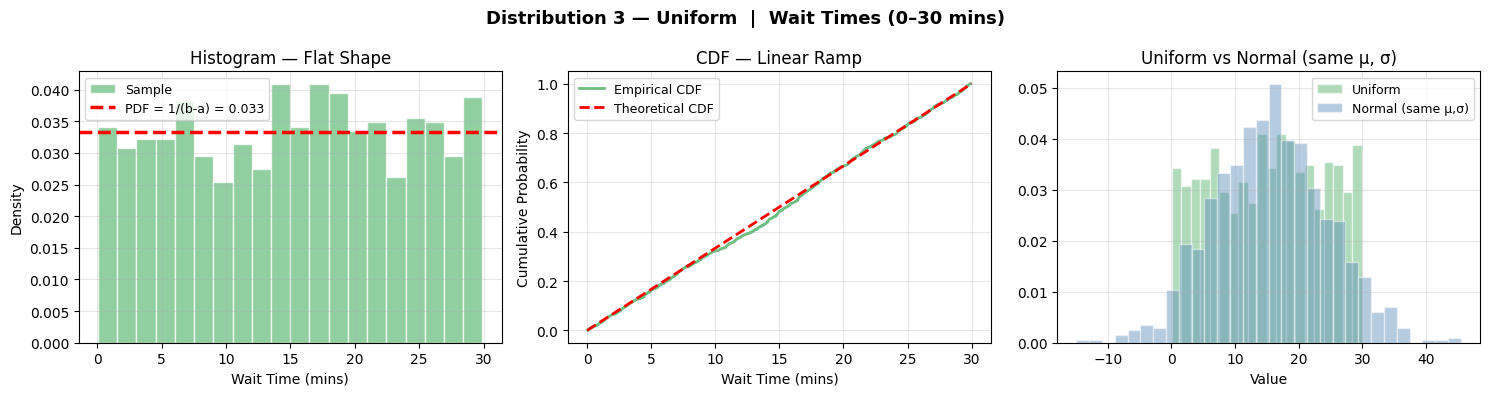

KS Test vs Uniform: stat=0.0334, p=0.2090 → Uniform ✓
Skewness: -0.0418  (≈0 expected for symmetric uniform)
Theoretical mean = 15.0  |  Sample mean = 15.21


In [7]:
# ── 6. Uniform Distribution ────────────────────────────────────────────────────
data = uniform_data
a, b = 0, 30

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribution 3 — Uniform  |  Wait Times (0–30 mins)', fontsize=13, fontweight='bold')

# Histogram — flat shape
ax = axes[0]
ax.hist(data, bins=20, density=True, color='#6DBF82', alpha=0.75, edgecolor='white', label='Sample')
ax.axhline(1/(b-a), color='red', lw=2.5, ls='--', label=f'PDF = 1/(b-a) = {1/(b-a):.3f}')
ax.set_title('Histogram — Flat Shape'); ax.set_xlabel('Wait Time (mins)'); ax.set_ylabel('Density')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# CDF — linear ramp
ax2 = axes[1]
sorted_data = np.sort(data)
cdf_empirical = np.arange(1, N+1) / N
ax2.plot(sorted_data, cdf_empirical, color='#6DBF82', lw=2, label='Empirical CDF')
x = np.linspace(a, b, 300)
ax2.plot(x, stats.uniform.cdf(x, loc=a, scale=b-a), 'r--', lw=2, label='Theoretical CDF')
ax2.set_title('CDF — Linear Ramp'); ax2.set_xlabel('Wait Time (mins)'); ax2.set_ylabel('Cumulative Probability')
ax2.legend(fontsize=9); ax2.grid(alpha=0.3)

# Comparison: Uniform vs Normal overlay
ax3 = axes[2]
ax3.hist(data, bins=20, density=True, alpha=0.55, color='#6DBF82', edgecolor='white', label='Uniform')
normal_equiv = np.random.normal(loc=data.mean(), scale=data.std(), size=N)
ax3.hist(normal_equiv, bins=30, density=True, alpha=0.45, color='#5B8DB8', edgecolor='white', label='Normal (same µ,σ)')
ax3.set_title('Uniform vs Normal (same µ, σ)'); ax3.set_xlabel('Value')
ax3.legend(fontsize=9); ax3.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'dist_uniform.png'), dpi=150, bbox_inches='tight')
plt.show()

# KS Test against uniform
ks_stat, ks_p = stats.kstest(data, 'uniform', args=(a, b-a))
print(f'KS Test vs Uniform: stat={ks_stat:.4f}, p={ks_p:.4f} → {"Uniform ✓" if ks_p>0.05 else "Not Uniform ✗"}')
print(f'Skewness: {stats.skew(data):.4f}  (≈0 expected for symmetric uniform)')
print(f'Theoretical mean = {(a+b)/2:.1f}  |  Sample mean = {data.mean():.2f}')

---
## 6. Distribution 4 — Binomial Distribution

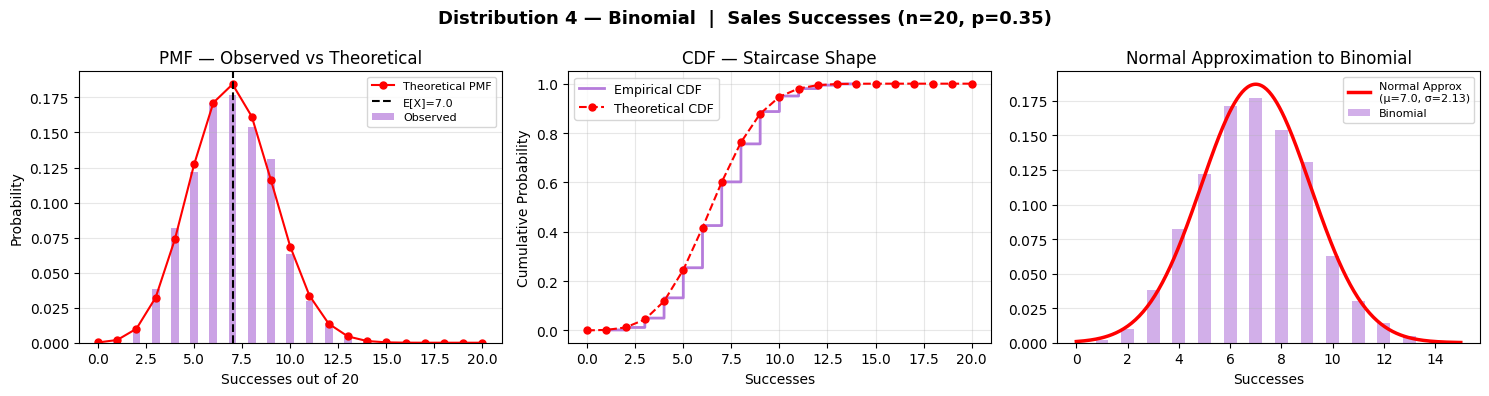

Theoretical mean = n×p = 20×0.35 = 7.0
Sample mean      = 6.957
Theoretical var  = n×p×(1-p) = 4.550
Sample variance  = 4.629
Skewness         = 0.1123


In [8]:
# ── 7. Binomial Distribution ───────────────────────────────────────────────────
data = binom_data
n_trials, p_success = 20, 0.35
theoretical_mean = n_trials * p_success
theoretical_var  = n_trials * p_success * (1 - p_success)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribution 4 — Binomial  |  Sales Successes (n=20, p=0.35)', fontsize=13, fontweight='bold')

# Bar chart — observed vs theoretical PMF
ax = axes[0]
unique, counts = np.unique(data, return_counts=True)
observed_prob = counts / N
x_pmf = np.arange(0, n_trials+1)
theoretical_pmf = stats.binom.pmf(x_pmf, n_trials, p_success)
ax.bar(unique, observed_prob, color='#B57BDB', alpha=0.7, label='Observed', width=0.4, align='center')
ax.plot(x_pmf, theoretical_pmf, 'ro-', markersize=5, lw=1.5, label='Theoretical PMF')
ax.axvline(theoretical_mean, color='black', ls='--', lw=1.5, label=f'E[X]={theoretical_mean:.1f}')
ax.set_title('PMF — Observed vs Theoretical'); ax.set_xlabel('Successes out of 20'); ax.set_ylabel('Probability')
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis='y')

# CDF — staircase
ax2 = axes[1]
sorted_data = np.sort(data)
cdf_empirical = np.arange(1, N+1) / N
ax2.step(sorted_data, cdf_empirical, where='post', color='#B57BDB', lw=2, label='Empirical CDF')
ax2.plot(x_pmf, stats.binom.cdf(x_pmf, n_trials, p_success), 'r--o',
         markersize=5, lw=1.5, label='Theoretical CDF')
ax2.set_title('CDF — Staircase Shape'); ax2.set_xlabel('Successes'); ax2.set_ylabel('Cumulative Probability')
ax2.legend(fontsize=9); ax2.grid(alpha=0.3)

# Normal approximation (works when np≥5 and n(1-p)≥5)
ax3 = axes[2]
ax3.bar(unique, observed_prob, color='#B57BDB', alpha=0.6, label='Binomial', width=0.5, align='center')
x_norm = np.linspace(data.min()-1, data.max()+1, 300)
normal_approx = stats.norm.pdf(x_norm, theoretical_mean, np.sqrt(theoretical_var))
ax3.plot(x_norm, normal_approx, 'r-', lw=2.5, label=f'Normal Approx\n(µ={theoretical_mean}, σ={np.sqrt(theoretical_var):.2f})')
ax3.set_title('Normal Approximation to Binomial'); ax3.set_xlabel('Successes')
ax3.legend(fontsize=8); ax3.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'dist_binomial.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'Theoretical mean = n×p = {n_trials}×{p_success} = {theoretical_mean}')
print(f'Sample mean      = {data.mean():.3f}')
print(f'Theoretical var  = n×p×(1-p) = {theoretical_var:.3f}')
print(f'Sample variance  = {data.var():.3f}')
print(f'Skewness         = {stats.skew(data):.4f}')

---
## 7. Side-by-Side Comparison — All Four Distributions

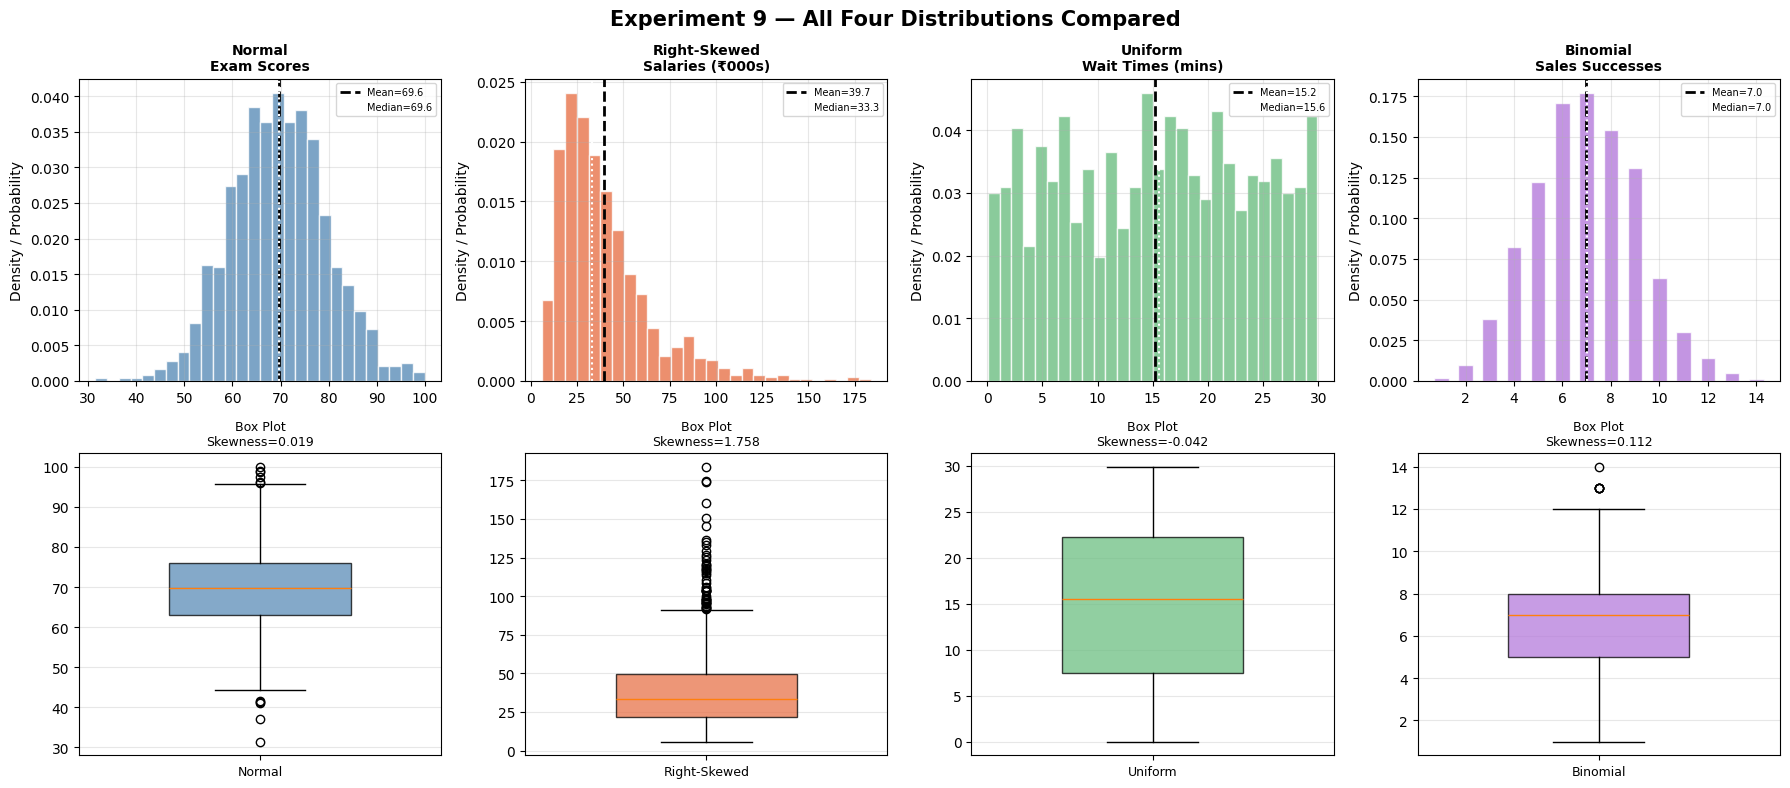

Comparison plot saved → dist_comparison.png ✓


In [9]:
# ── 8. Master Comparison Plot ──────────────────────────────────────────────────
dist_list   = ['Normal', 'Right-Skewed', 'Uniform', 'Binomial']
data_list   = [normal_data, skewed_data, uniform_data, binom_data]
colors_list = ['#5B8DB8', '#E8734A', '#6DBF82', '#B57BDB']
subtitles   = ['Exam Scores', 'Salaries (₹000s)', 'Wait Times (mins)', 'Sales Successes']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Experiment 9 — All Four Distributions Compared', fontsize=15, fontweight='bold')

for col, (name, data, color, subtitle) in enumerate(zip(dist_list, data_list, colors_list, subtitles)):

    # Top row: histogram
    ax_top = axes[0, col]
    if name == 'Binomial':
        unique, counts = np.unique(data, return_counts=True)
        ax_top.bar(unique, counts/N, color=color, alpha=0.8, edgecolor='white', width=0.6)
    else:
        ax_top.hist(data, bins=28, density=True, color=color, alpha=0.8, edgecolor='white')
    ax_top.axvline(data.mean(),   color='black',  lw=2,   ls='--', label=f'Mean={data.mean():.1f}')
    ax_top.axvline(np.median(data), color='white', lw=1.5, ls=':',  label=f'Median={np.median(data):.1f}')
    ax_top.set_title(f'{name}\n{subtitle}', fontweight='bold', fontsize=10)
    ax_top.set_ylabel('Density / Probability')
    ax_top.legend(fontsize=7); ax_top.grid(alpha=0.3)

    # Bottom row: box plot
    ax_bot = axes[1, col]
    bp = ax_bot.boxplot(data, vert=True, patch_artist=True, widths=0.5)
    bp['boxes'][0].set_facecolor(color); bp['boxes'][0].set_alpha(0.75)
    skew_val = stats.skew(data)
    ax_bot.set_title(f'Box Plot\nSkewness={skew_val:.3f}', fontsize=9)
    ax_bot.set_xticklabels([name], fontsize=9)
    ax_bot.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'dist_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Comparison plot saved → dist_comparison.png ✓')

---
## 8. Final Summary Table

In [10]:
# ── 9. Final Summary Table ─────────────────────────────────────────────────────
summary_rows = []
for name, data in distributions.items():
    w, p_sw   = stats.shapiro(data[:200])
    skew_val  = stats.skew(data)
    kurt_val  = stats.kurtosis(data)
    shape     = ('Symmetric'   if abs(skew_val) < 0.5
                 else 'Right-skewed' if skew_val > 0.5
                 else 'Left-skewed')
    summary_rows.append({
        'Distribution':    name,
        'Mean':            round(data.mean(), 3),
        'Median':          round(np.median(data), 3),
        'Std Dev':         round(data.std(), 3),
        'Skewness':        round(skew_val, 3),
        'Kurtosis':        round(kurt_val, 3),
        'Shape':           shape,
        'Shapiro p-val':   round(p_sw, 4),
        'Normal?':         'Yes ✓' if p_sw > 0.05 else 'No ✗'
    })

df_summary = pd.DataFrame(summary_rows)

def highlight_normal(row):
    if row['Normal?'] == 'Yes ✓': return ['background-color:#d4edda'] * len(row)
    if 'skewed' in row['Shape']:  return ['background-color:#FFE0B2'] * len(row)
    return [''] * len(row)

(df_summary.style
 .apply(highlight_normal, axis=1)
 .set_caption('Experiment 9 — Distribution Summary Table  (green=normal, orange=skewed)')
 .set_properties(**{'text-align':'center','padding':'7px 14px','border':'1px solid #ddd'})
 .set_table_styles([{'selector':'th','props':'background-color:#2c3e50;color:white;text-align:center;padding:8px;'},
                    {'selector':'caption','props':'font-size:14px;font-weight:bold;padding-bottom:8px;'}])
)

,Distribution,Mean,Median,Std Dev,Skewness,Kurtosis,Shape,Shapiro p-val,Normal?
0,Normal,69.594000,69.644000,9.942000,0.019000,0.145000,Symmetric,0.556600,Yes ✓
1,Right-Skewed,39.695000,33.289000,25.361000,1.758000,4.329000,Right-skewed,0.000000,No ✗
2,Uniform,15.214000,15.566000,8.581000,-0.042000,-1.159000,Symmetric,0.000200,No ✗
3,Binomial,6.957000,7.000000,2.152000,0.112000,-0.194000,Symmetric,0.001900,No ✗


---
## 📚 Distribution Quick Reference

| Distribution | Skewness | Mean vs Median | Kurtosis | Use When |
|---|---|---|---|---|
| **Normal** | ≈ 0 | Equal | ≈ 0 (mesokurtic) | Heights, errors, test scores |
| **Right-Skewed** | > 0 | Mean > Median | > 0 (leptokurtic) | Salaries, house prices, wait times |
| **Uniform** | ≈ 0 | Equal | < 0 (platykurtic) | Random draws, equal probability events |
| **Binomial** | Depends on p | Depends on p | Discrete | Count of successes in n trials |

**Key rules:**
- Skewness ≈ 0 → symmetric distribution
- Skewness > 0.5 → right tail (mean pulled right)
- Skewness < -0.5 → left tail (mean pulled left)
- Kurtosis > 0 → heavier tails than normal (more outliers)
- Kurtosis < 0 → lighter tails than normal (fewer outliers)
- Normal approximation to Binomial is valid when **n×p ≥ 5** and **n×(1-p) ≥ 5**